# Data Visualization of Object Detection Metrics

This notebook visualizes the distribution of instance counts and average
bounding box areas, along with the relationship between these two metrics in
object detection training data.


In [1]:
%pip install -q seaborn SciencePlots

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import scienceplots

plt.style.use(["science", "nature"])

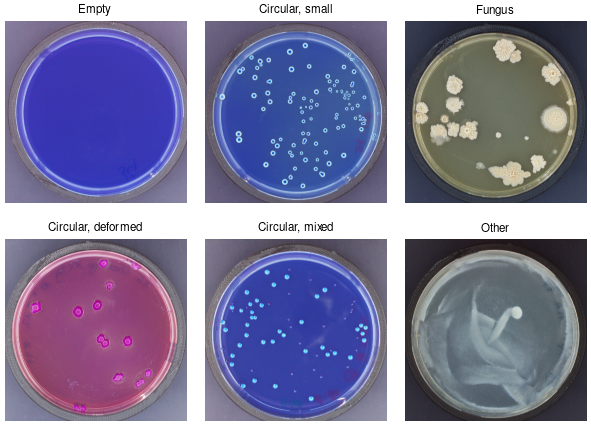

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(6, 4))

axs[0][0].imshow(
    plt.imread(
        "./train_data/images/cocci_aerococcus_viridans_34_default_mmrsbpb_3_07102022161025.jpg"
    )
)
axs[0][0].set_title("Empty")

axs[0][1].imshow(
    plt.imread(
        "./train_data/images/cocci_aerococcus_viridans_34_default_mmrsbpb_4_18112022130303.jpg"
    )
)
axs[0][1].set_title("Circular, small")

axs[0][2].imshow(
    plt.imread("./train_data/images/default_mmrsagar_default_12122023115025.jpg")
)
axs[0][2].set_title("Fungus")

axs[1][0].imshow(
    plt.imread("./train_data/images/default_mmrsagar_default_12122023115101.jpg")
)
axs[1][0].set_title("Circular, deformed")

axs[1][1].imshow(
    plt.imread("./train_data/images/default_mmrsagar_mMRS-BPB_12122023121413.jpg")
)
axs[1][1].set_title("Circular, mixed")

axs[1][2].imshow(
    plt.imread(
        "./train_data/images/13_100µl_2 _default_ gvpcagar_default_15122023144544.jpg"
    )
)
axs[1][2].set_title("Other")

# Remove axis ticks and labels
for ax in axs:
    for a in ax:
        a.axis("off")

fig.subplots_adjust(wspace=0, left=0, right=1, top=1, bottom=0)

plt.savefig("chart_image_types.png", dpi=500)
plt.show()

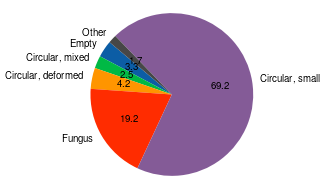

In [4]:
labels = [
    "Empty",
    "Circular, mixed",
    "Circular, deformed",
    "Fungus",
    "Circular, small",
    "Other",
]
sizes = [4, 3, 5, 23, 83, 2]

# Create the pie chart
plt.figure(figsize=(3, 2))
plt.pie(sizes, labels=labels, autopct="%1.1f%%", startangle=140)
plt.axis("equal")  # Equal aspect ratio ensures that pie is drawn as a circle.

plt.tight_layout()
plt.savefig("chart_image_types_pie.png", dpi=500)
plt.show()

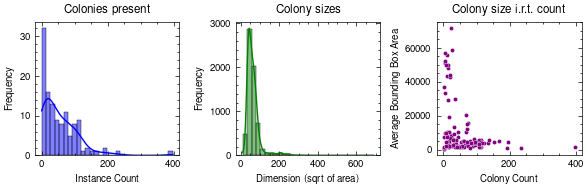

In [5]:
import pandas as pd
import numpy as np

box_data = pd.read_csv("./train_data/box_data.csv")
metadata = pd.read_csv("./train_data/metadata.csv")

# Calculate the bounding box dimensions (sqrt of area)
box_data["dimension"] = np.sqrt(box_data["area"])

average_area_per_file = box_data.groupby("filename")["area"].mean()

merged_data = metadata.set_index("filename").join(
    average_area_per_file.rename("average_area")
)
merged_data.reset_index(inplace=True)

fig, axs = plt.subplots(1, 3, figsize=(6, 2))

# Plot 1: Histogram of Instance Counts
sns.histplot(metadata["instance_count"], ax=axs[0], bins=30, kde=True, color="blue")
axs[0].set_title("Colonies present")
axs[0].set_xlabel("Instance Count")
axs[0].set_ylabel("Frequency")

# Plot 2: Histogram of Bounding Box Dimensions
sns.histplot(box_data["dimension"], ax=axs[1], bins=30, kde=True, color="green")
axs[1].set_title("Colony sizes")
axs[1].set_xlabel("Dimension (sqrt of area)")
axs[1].set_ylabel("Frequency")

# Plot 3: Scatter Plot of Instance Count vs Average Bounding Box Area
sns.scatterplot(
    data=merged_data, x="instance_count", y="average_area", ax=axs[2], color="purple"
)
axs[2].set_title("Colony size i.r.t. count")
axs[2].set_xlabel("Colony Count")
axs[2].set_ylabel("Average Bounding Box Area")

plt.tight_layout()
plt.savefig("chart_labeling_distribution.png", dpi=500)
plt.show()